BÀI THỰC HÀNH SỐ 1 - SPARKSQL: KHÁM PHÁ, XỬ LÝ VÀ PHÂN TÍCH DỮ LIỆU NYC TAXI
Tập dữ liệu: NYC Yellow Taxi 2023 (Tệp Parquet các tháng) & Taxi Zone Lookup (Tệp CSV).
Mục tiêu: Xây dựng quy trình xử lý dữ liệu (Data Pipeline) từ dữ liệu thô đến báo cáo phân tích theo chuẩn kỹ thuật Data Engineering chuyên nghiệp.

### Kết quả lần chạy đã lưu
Đã chạy toàn bộ 5.980.721 bản ghi của tháng 01–02/2023, giữ 5.515.455 chuyến sau làm sạch.
Có **279** chuyến trả khách trước khi đón, tổng `total_amount` **10.585,13 USD**.
Biến tương quan mạnh nhất với tổng tiền là `fare_amount` (`r = 0,979912`).
Các bảng, biểu đồ và phép đo bên dưới thuộc lần chạy này; thời gian benchmark phụ thuộc máy và bộ đệm.

Các thuộc tính chính trong bộ dữ liệu:
1.	VendorID: Mã chỉ định nhà cung cấp dịch vụ taxi (Creative Mobile Technologies hoặc VeriFone Inc.).
2.	tpep_pickup_datetime: Thời gian khi đồng hồ tính tiền bắt đầu.
3.	tpep_dropoff_datetime: Thời gian khi đồng hồ tính tiền dừng.
4.	Passenger_count: Số lượng hành khách trong xe (giá trị do tài xế nhập).
5.	Trip_distance: Khoảng cách chuyến đi tính bằng dặm.
6.	PULocationID: Mã vùng đón khách, tra tên vùng/quận bằng bảng Taxi Zone Lookup.
7.	RateCodeID: Mã loại giá áp dụng cho chuyến đi (ví dụ: giá chuẩn, giá sân bay JFK, giá thỏa thuận…).
8.	Store_and_fwd_flag: Cờ cho biết liệu chuyến đi có bị tạm lưu trong bộ nhớ xe do mất kết nối với máy chủ hay không.
9.	DOLocationID: Mã vùng trả khách, tra tên vùng/quận bằng bảng Taxi Zone Lookup.
10.	Payment_type: Hình thức thanh toán (tiền mặt, thẻ tín dụng, không tính phí…).
11.	Fare_amount: Cước phí chuyến đi tính theo thời gian và khoảng cách.
12.	Extra: Các phụ phí như phí giờ cao điểm, phí qua đêm.
13.	MTA_tax: Thuế MTA tự động áp dụng cho chuyến đi.
14.	Improvement_surcharge: Phụ phí cải tiến áp dụng từ năm 2015.
15.	Tip_amount: Tiền tip (chỉ tính với thẻ tín dụng, không tính tiền tip bằng tiền mặt).
16.	Tolls_amount: Tổng tiền phí cầu đường phải trả trong chuyến đi.
17.	Total_amount: Tổng số tiền hành khách phải trả (không bao gồm tiền tip bằng tiền mặt).

Bản dữ liệu năm 2023 đang dùng có mã vùng đón/trả, không có các cột kinh độ/vĩ độ của định dạng taxi cũ.

## Lời giải và cách chạy
Chạy tuần tự từ đầu. Notebook dùng toàn bộ hai tháng 01–02/2023 từ [NYC TLC](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).
Các bảng và kết luận dưới từng bài được tính khi chạy, không điền số ước lượng.
Môi trường: Python 3.12, Java 21, PySpark 4.0.2; cài theo `requirements.txt` trong thư mục lời giải.
Giờ phân tích được giữ theo thời gian địa phương ghi trong tệp (`America/New_York`).

In [1]:
import os
from pathlib import Path
# Có thể mở notebook từ thư mục gốc hoặc từ loi_giai/.
ROOT = Path.cwd().resolve()
if ROOT.name == 'loi_giai':
    ROOT = ROOT.parent
os.chdir(ROOT)
import sys
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ.setdefault('SPARK_LOCAL_IP', '127.0.0.1')

'127.0.0.1'

BƯỚC 1: TẢI DỮ LIỆU VÀ CHUẨN BỊ MÔI TRƯỜNG
Học viên chạy đoạn mã Python sau để tự động tải các tệp dữ liệu về thư mục local ./nyc_data:

In [2]:
import os
import urllib.request

# Tạo thư mục lưu trữ
os.makedirs("./nyc_data", exist_ok=True)

# Danh sách URL dữ liệu taxi NYC năm 2023 và bảng tra cứu
urls = {
    "yellow_tripdata_2023-01.parquet": "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet",
    "yellow_tripdata_2023-02.parquet": "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-02.parquet",
    "taxi_zone_lookup.csv": "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
}

for file_name, url in urls.items():
    file_path = os.path.join("./nyc_data", file_name)
    if not os.path.exists(file_path):
        print(f"Đang tải {file_name}...")
        urllib.request.urlretrieve(url, file_path)
        print(f"Đã tải: {file_name}")
    else:
        print(f"⚡ File đã tồn tại: {file_name}")

⚡ File đã tồn tại: yellow_tripdata_2023-01.parquet
⚡ File đã tồn tại: yellow_tripdata_2023-02.parquet
⚡ File đã tồn tại: taxi_zone_lookup.csv


BƯỚC 2: KHỞI TẠO SPARK SESSION VỚI CẤU HÌNH ỔN ĐỊNH


In [3]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("NYC_Taxi_BigData_Lab") \
    .master("local[2]") \
    .config("spark.driver.memory", "2g") \
    .config("spark.sql.shuffle.partitions", "16") \
    .config("spark.sql.session.timeZone", "America/New_York") \
    .config("spark.ui.enabled", "false") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()

print("Spark Session đã được khởi tạo thành công!")
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 21:57:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark Session đã được khởi tạo thành công!


BƯỚC 3: NẠP DỮ LIỆU & CHUẨN HÓA SCHEMA KHÔNG ĐỒNG NHẤT
Dữ liệu thực tế giữa các tháng thường bị lệch kiểu (INT vs BIGINT, DOUBLE vs BIGINT) và tên cột (Airport_fee vs airport_fee). Chúng ta áp dụng giải pháp ép kiểu tối giản dựa trên Schema khuôn mẫu của Tháng 1.

In [4]:
from pyspark.sql import functions as F
# 1. Nạp tệp Tháng 1 (Làm khuôn mẫu Schema) và Tháng 2
df1 = spark.read.parquet("./nyc_data/yellow_tripdata_2023-01.parquet")
df2 = spark.read.parquet("./nyc_data/yellow_tripdata_2023-02.parquet")

# 2. Chuẩn hóa tên cột bị lệch chữ hoa/thường ở df2
df2 = df2.withColumnRenamed("Airport_fee", "airport_fee")

# 3. Ép toàn bộ kiểu dữ liệu của df2 theo Schema khuôn mẫu của df1
df2 = df2.select([F.col(col.name).cast(col.dataType) for col in df1.schema])

# 4. Hợp nhất hai DataFrame
df_raw = df1.union(df2)

# 5. Nạp bảng danh mục khu vực (CSV)
df_zones = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("./nyc_data/taxi_zone_lookup.csv")

total_records = df_raw.count()
print(f"Tổng số bản ghi nạp vào: {total_records:,} dòng")

Tổng số bản ghi nạp vào: 5,980,721 dòng


BƯỚC 4: KHÁM PHÁ DỮ LIỆU CHUYÊN SÂU (EDA) & THỐNG KÊ HÌNH DẠNG
4.1 Thống kê mô tả và kiểm tra giá trị khuyết thiếu (NULL)

In [5]:
# 1. Thống kê phân vị cơ bản
numeric_cols = ["passenger_count", "trip_distance", "fare_amount", "tip_amount", "total_amount"]
print("=== BÁO CÁO THỐNG KÊ MÔ TẢ ===")
df_raw.select(numeric_cols).summary("count", "mean", "stddev", "min", "50%", "max").show()

# 2. Kiểm tra số lượng NULL trên tất cả các cột bằng List Comprehension
null_counts = df_raw.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c) 
    for c in df_raw.columns
])
print("=== SỐ LƯỢNG GIÁ TRỊ NULL THEO CỘT ===")
null_counts.show(vertical=True)

=== BÁO CÁO THỐNG KÊ MÔ TẢ ===


+-------+------------------+------------------+------------------+-----------------+------------------+
|summary|   passenger_count|     trip_distance|       fare_amount|       tip_amount|      total_amount|
+-------+------------------+------------------+------------------+-----------------+------------------+
|  count|           5832161|           5980721|           5980721|          5980721|           5980721|
|   mean|1.3578207117396108|3.8574354630484002|18.295598793189132| 3.37616698388113|26.960991094487895|
| stddev|0.8927377984327337| 258.9361158969996|17.657792913093825|3.832283059004118|22.007135702165705|
|    min|               0.0|               0.0|            -900.0|           -96.22|           -757.55|
|    50%|               1.0|              1.79|              12.8|             2.75|             20.16|
|    max|               9.0|         335004.33|            2203.1|            482.9|            2208.1|
+-------+------------------+------------------+-----------------

-RECORD 0-----------------------
 VendorID              | 0      
 tpep_pickup_datetime  | 0      
 tpep_dropoff_datetime | 0      
 passenger_count       | 148560 
 trip_distance         | 0      
 RatecodeID            | 148560 
 store_and_fwd_flag    | 148560 
 PULocationID          | 0      
 DOLocationID          | 0      
 payment_type          | 0      
 fare_amount           | 0      
 extra                 | 0      
 mta_tax               | 0      
 tip_amount            | 0      
 tolls_amount          | 0      
 improvement_surcharge | 0      
 total_amount          | 0      
 congestion_surcharge  | 148560 
 airport_fee           | 148560 



4.2 Thống kê Độ lệch (Skewness), Độ nhọn (Kurtosis) & Tương quan (Pearson Matrix)

=== THỐNG KÊ SKEWNESS VÀ KURTOSIS ===


-RECORD 0--------------------------------
 trip_distance_skewness     | 856.934    
 trip_distance_kurtosis     | 860257.826 
 fare_amount_skewness       | 3.543      
 fare_amount_kurtosis       | 87.063     
 tip_amount_skewness        | 5.711      
 tip_amount_kurtosis        | 271.166    
 total_amount_skewness      | 2.998      
 total_amount_kurtosis      | 42.692     
 trip_duration_min_skewness | 33.64      
 trip_duration_min_kurtosis | 1740.552   



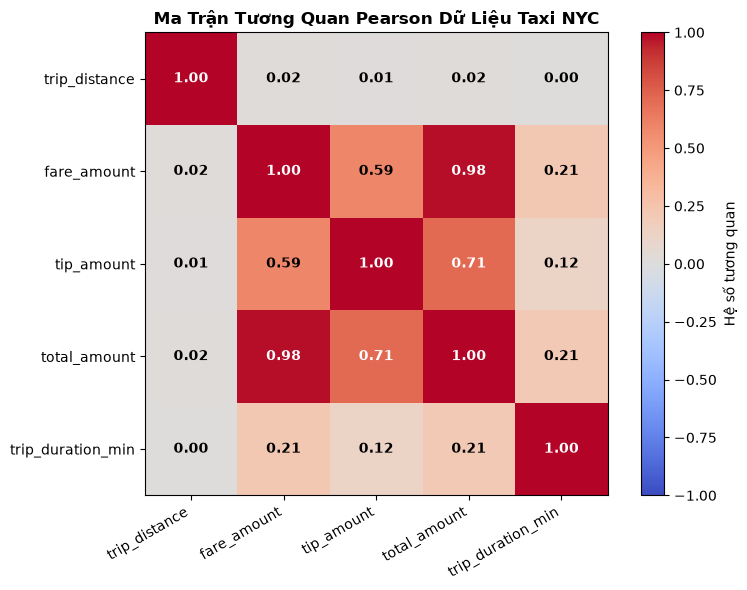

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Tính toán các cờ thời gian tạm thời để phân tích
df_eda = df_raw \
    .withColumn("trip_duration_min", F.round((F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60, 2))

# 1. Tính Skewness & Kurtosis
stat_cols = ["trip_distance", "fare_amount", "tip_amount", "total_amount", "trip_duration_min"]
skew_kurt_exprs = []
for c in stat_cols:
    skew_kurt_exprs.append(F.round(F.skewness(c), 3).alias(f"{c}_skewness"))
    skew_kurt_exprs.append(F.round(F.kurtosis(c), 3).alias(f"{c}_kurtosis"))

print("=== THỐNG KÊ SKEWNESS VÀ KURTOSIS ===")
df_eda.select(skew_kurt_exprs).show(vertical=True)

# 2. Tính Ma trận Tương quan Pearson
pairs = [(a, b) for a in stat_cols for b in stat_cols]
corr_row = df_eda.agg(*[F.corr(a,b).alias(f"corr_{i}") for i,(a,b) in enumerate(pairs)]).first()
correlations = {pair: corr_row[i] for i,pair in enumerate(pairs)}
corr_matrix = []
for c1 in stat_cols:
    row = []
    for c2 in stat_cols:
        val = correlations[(c1, c2)]
        row.append(round(val, 3) if val is not None else np.nan)
    corr_matrix.append(row)

df_corr = pd.DataFrame(corr_matrix, index=stat_cols, columns=stat_cols)

# 3. Trực quan hóa Heatmap Tương quan bằng Matplotlib thuần
plt.figure(figsize=(8, 6))
im = plt.imshow(df_corr.values, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, label="Hệ số tương quan")
plt.xticks(np.arange(len(stat_cols)), stat_cols, rotation=30, ha="right")
plt.yticks(np.arange(len(stat_cols)), stat_cols)

for i in range(len(stat_cols)):
    for j in range(len(stat_cols)):
        color = "white" if abs(df_corr.values[i, j]) > 0.6 else "black"
        plt.text(j, i, f"{df_corr.values[i, j]:.2f}", ha="center", va="center", color=color, fontweight="bold")

plt.title("Ma Trận Tương Quan Pearson Dữ Liệu Taxi NYC", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

Bài tập 1 (Phân tích EDA):
Dựa vào kết quả thu được, hãy lý giải:
+ Tại sao trip_distance có Skewness và Kurtosis tăng vọt? Điều này báo hiệu điều gì về chất lượng dữ liệu?
+ Dựa vào Ma trận Tương quan, cặp biến nào có tương quan tuyến tính mạnh nhất với total_amount?

### Lời giải bài 1

**Tại sao trip_distance có Skewness và Kurtosis tăng vọt?**

- **Skewness (độ lệch) dương lớn:** phần lớn chuyến đi có quãng đường tương đối ngắn, nhưng một số ít chuyến có quãng đường rất lớn. Nếu vẽ biểu đồ với quãng đường tăng từ trái sang phải, các giá trị rất lớn này nằm xa về phía bên phải. Đó là ý nghĩa của cách nói dữ liệu “lệch phải”.
- **Kurtosis rất lớn:** dữ liệu có những giá trị cách xa mức thông thường. Những giá trị này có thể kéo số trung bình lên cao và làm độ lệch chuẩn tăng mạnh, nên hai chỉ số đó có thể không phản ánh tốt một chuyến đi thông thường. Spark tính chỉ số này theo dạng *excess kurtosis*, trong đó phân phối chuẩn có giá trị bằng 0.

**Điều này báo hiệu điều gì về chất lượng dữ liệu?**

Cần kiểm tra các chuyến có quãng đường lớn bất thường. Nguyên nhân có thể là lỗi GPS, lỗi đồng hồ đo hoặc nhập sai dữ liệu, nhưng cũng có thể là chuyến đi dài thực tế. Vì vậy, cần đối chiếu quãng đường với thời gian di chuyển và vận tốc trước khi quyết định loại bỏ bản ghi.

**Dựa vào Ma trận Tương quan, cặp biến nào có tương quan tuyến tính mạnh nhất với total_amount?**

Đoạn code bên dưới so sánh hệ số tương quan của từng biến với `total_amount` và chọn biến có **giá trị tuyệt đối của hệ số lớn nhất**. Không xét `total_amount` với chính nó. Hệ số dương cho biết hai biến thường tăng hoặc giảm cùng nhau; hệ số âm cho biết chúng thường thay đổi ngược chiều.

Tổng tiền bao gồm các khoản như tiền cước và tiền tip, nên các khoản này có thể có tương quan cao với tổng tiền vì chúng là thành phần của phép cộng. Tương quan cao tự nó không đủ để kết luận quan hệ nguyên nhân – kết quả.

In [7]:
corr_total = [(name, correlations[(name, 'total_amount')])
              for name in stat_cols if name != 'total_amount']
corr_total = [(name, value) for name, value in corr_total if value is not None and np.isfinite(value)]
corr_total.sort(key=lambda x: abs(x[1]), reverse=True)
for name, value in corr_total:
    print(f'{name:22s}: r = {value:.6f}')
if corr_total:
    print('Biến tương quan tuyến tính mạnh nhất với total_amount:', corr_total[0][0])

fare_amount           : r = 0.979912
tip_amount            : r = 0.707295
trip_duration_min     : r = 0.206148
trip_distance         : r = 0.015728
Biến tương quan tuyến tính mạnh nhất với total_amount: fare_amount


BƯỚC 5: PHÁT HIỆN DỮ LIỆU BẤT THƯỜNG (ANOMALY DETECTION) & LÀM SẠCH
5.1 Gán cờ báo lỗi logic (Anomaly Flagging) & Thống kê

In [8]:
# Gán cờ báo hiệu bất thường dạng Array
df_flagged = df_eda \
    .withColumn("speed_mph", F.when(F.col("trip_duration_min") > 0, F.round(F.col("trip_distance") / (F.col("trip_duration_min") / 60), 2))) \
    .withColumn("anomaly_reasons", F.array(
        F.when(F.col("passenger_count").isNull() | (F.col("passenger_count") <= 0), "INVALID_PASSENGER"),
        F.when(F.col("trip_distance").isNull() | (F.col("trip_distance") <= 0), "ZERO_OR_NEGATIVE_DISTANCE"),
        F.when(F.col("total_amount").isNull() | (F.col("total_amount") <= 0), "ZERO_OR_NEGATIVE_FARE"),
        F.when(F.col("trip_duration_min").isNull() | (F.col("trip_duration_min") <= 0), "INVALID_DURATION"),
        F.when(F.col("trip_duration_min") > 1440, "EXCESSIVE_DURATION"),
        F.when(F.col("speed_mph") > 100, "EXCESSIVE_SPEED"),
        F.when(F.col("PULocationID").isin(264, 265) | F.col("DOLocationID").isin(264, 265), "UNKNOWN_LOCATION")
    )) \
    .withColumn("anomaly_reasons", F.filter("anomaly_reasons", lambda x: x.isNotNull()))

# Thống kê chi tiết các dạng lỗi
print("=== BÁO CÁO TỔNG HỢP CÁC DẠNG BẤT THƯỜNG ===")
df_flagged \
    .filter(F.size("anomaly_reasons") > 0) \
    .select(F.explode("anomaly_reasons").alias("anomaly_type")) \
    .groupBy("anomaly_type") \
    .agg(F.count("*").alias("error_count")) \
    .withColumn("pct_of_total", F.round((F.col("error_count") / total_records) * 100, 2)) \
    .orderBy(F.desc("error_count")) \
    .show(truncate=False)

=== BÁO CÁO TỔNG HỢP CÁC DẠNG BẤT THƯỜNG ===


+-------------------------+-----------+------------+
|anomaly_type             |error_count|pct_of_total|
+-------------------------+-----------+------------+
|INVALID_PASSENGER        |247001     |4.13        |
|UNKNOWN_LOCATION         |111678     |1.87        |
|ZERO_OR_NEGATIVE_DISTANCE|86960      |1.45        |
|ZERO_OR_NEGATIVE_FARE    |51238      |0.86        |
|EXCESSIVE_SPEED          |3075       |0.05        |
|INVALID_DURATION         |2386       |0.04        |
|EXCESSIVE_DURATION       |47         |0.0         |
+-------------------------+-----------+------------+



5.2 Xử lý Outlier theo Phương pháp Phân vị P99.9 & Lọc dữ liệu sạch

In [9]:
# Tính ngưỡng P99.9 cho quãng đường di chuyển
p999_dist = df_raw.approxQuantile("trip_distance", [0.999], 0.0001)[0]
print(f"Ngưỡng Outlier Quãng đường (P99.9): {p999_dist:.2f} miles")

# Lọc tập dữ liệu sạch hoàn toàn
df_clean = df_flagged \
    .filter(
        (F.size("anomaly_reasons") == 0) & 
        (F.col("trip_distance") <= p999_dist)
    ) \
    .withColumn("pickup_date", F.col("tpep_pickup_datetime").cast("date")) \
    .drop("anomaly_reasons")

clean_records = df_clean.count()
print(f"Dữ liệu sạch còn lại: {clean_records:,} dòng (Đã loại bỏ {total_records - clean_records:,} dòng lỗi)")

Ngưỡng Outlier Quãng đường (P99.9): 28.63 miles


Dữ liệu sạch còn lại: 5,515,455 dòng (Đã loại bỏ 465,266 dòng lỗi)


Lưu lại dữ liệu đã làm sạch

In [10]:
output_path = "./nyc_data/yellow_tripdata_2023-01-02-parquet"

df_clean.write \
    .mode("overwrite") \
    .parquet(output_path)

print(f"Đã ghi tập dữ liệu sạch thành công vào: {output_path}")

Đã ghi tập dữ liệu sạch thành công vào: ./nyc_data/yellow_tripdata_2023-01-02-parquet


Bài tập 2 (Anomaly Detection):
Viết câu lệnh đếm số lượng chuyến đi bị lỗi thời gian ngược (thời gian trả khách tpep_dropoff_datetime xảy ra trước thời gian đón khách tpep_pickup_datetime). Tính tổng thất thu tiền cước (total_amount) từ các chuyến đi bị lỗi này.

In [11]:
reverse_time = df_raw.filter(F.col('tpep_dropoff_datetime') < F.col('tpep_pickup_datetime'))
reverse_time.agg(
    F.count('*').alias('so_chuyen_loi_thoi_gian'),
    F.count('total_amount').alias('so_chuyen_co_so_tien'),
    F.round(F.coalesce(F.sum('total_amount'), F.lit(0.0)), 2).alias('tong_total_amount_USD'),
    F.round(F.coalesce(F.sum(F.when(F.col('total_amount') > 0, F.col('total_amount')).otherwise(0)), F.lit(0.0)), 2).alias('tong_tien_duong_bi_loai_USD')
).show(truncate=False)

+-----------------------+--------------------+---------------------+---------------------------+
|so_chuyen_loi_thoi_gian|so_chuyen_co_so_tien|tong_total_amount_USD|tong_tien_duong_bi_loai_USD|
+-----------------------+--------------------+---------------------+---------------------------+
|279                    |279                 |10585.13             |10585.13                   |
+-----------------------+--------------------+---------------------+---------------------------+



Lọc trên `df_raw` vì dữ liệu sạch đã loại thời gian không hợp lệ. Dấu `<` không tính chuyến có hai mốc bằng nhau.
`tong_total_amount_USD` là tổng có dấu theo đề; tổng dương cho biết tiền dương gắn với bản ghi bị loại.
Đây là doanh thu liên quan đến bản ghi lỗi, chưa đủ bằng chứng gọi là khoản tiền thực sự không thu được.

BƯỚC 6: MULTI-JOIN, AGGREGATION & XOAY BẢNG DỮ LIỆU (PIVOT)

6.1 Multi-JOIN & Lọc bỏ giá trị không xác định

In [12]:
# Join với bảng danh mục Zone
df_joined = df_clean \
    .join(df_zones, df_clean.PULocationID == df_zones.LocationID, "left") \
    .withColumnRenamed("Borough", "pickup_borough") \
    .withColumnRenamed("Zone", "pickup_zone") \
    .drop("LocationID")

# Báo cáo tổng doanh thu theo Quận (Loại bỏ hoàn toàn 'Unknown', 'N/A' và NULL)
df_borough_summary = df_joined \
    .filter(
        F.col("pickup_borough").isNotNull() & 
        (~F.col("pickup_borough").isin("Unknown", "N/A"))
    ) \
    .groupBy("pickup_borough") \
    .agg(
        F.count("*").alias("total_trips"),
        F.round(F.sum("total_amount"), 2).alias("total_revenue")
    ) \
    .orderBy(F.desc("total_revenue"))

df_borough_summary.show()

+--------------+-----------+--------------+
|pickup_borough|total_trips| total_revenue|
+--------------+-----------+--------------+
|     Manhattan|    4999130|1.1350419867E8|
|        Queens|     485168| 3.358947611E7|
|      Brooklyn|      25061|     781972.69|
|         Bronx|       5578|     187236.56|
| Staten Island|        424|      26783.37|
|           EWR|         94|       9060.61|
+--------------+-----------+--------------+



6.2 Bảng Xoay Ma trận (Pivot Table Optimization)
Thực hiện Pivot tạo ma trận doanh thu giữa các Quận (Hàng) và Thứ trong tuần (Cột). Truyền danh sách cột cố định để tối ưu hóa hiệu năng Spark.

In [13]:
# Thêm cột viết tắt ngày trong tuần
df_joined_day = df_joined \
    .filter(F.col("pickup_borough").isNotNull() & (~F.col("pickup_borough").isin("Unknown", "N/A"))) \
    .withColumn("day_of_week", F.date_format("pickup_date", "E"))

pivot_days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

df_pivot_revenue = df_joined_day \
    .groupBy("pickup_borough") \
    .pivot("day_of_week", pivot_days) \
    .agg(F.round(F.sum("total_amount"), 2)) \
    .fillna(0)

print("=== MA TRẬN DOANH THU THEO QUẬN VÀ NGÀY TRONG TUẦN (PIVOT) ===")
df_pivot_revenue.show(truncate=False)

=== MA TRẬN DOANH THU THEO QUẬN VÀ NGÀY TRONG TUẦN (PIVOT) ===


+--------------+-------------+-------------+-------------+-------------+-------------+-------------+-------------+
|pickup_borough|Mon          |Tue          |Wed          |Thu          |Fri          |Sat          |Sun          |
+--------------+-------------+-------------+-------------+-------------+-------------+-------------+-------------+
|EWR           |1283.7       |974.5        |319.96       |709.71       |2511.09      |799.25       |2462.4       |
|Staten Island |4087.89      |3644.92      |4036.04      |3575.95      |3565.76      |3447.72      |4425.09      |
|Bronx         |28487.26     |33574.24     |31120.01     |31222.3      |30310.4      |16538.16     |15984.19     |
|Brooklyn      |97563.24     |108470.85    |106243.23    |113324.0     |110945.64    |118222.19    |127203.54    |
|Manhattan     |1.358329266E7|1.717001441E7|1.671523304E7|1.773455792E7|1.716272743E7|1.653737763E7|1.460099558E7|
|Queens        |5888395.64   |5191859.97   |4216401.71   |4514023.89   |4684205.

Bài tập 3 (Pivot Table):
Hãy tạo ma trận Pivot đếm Số lượng chuyến đi (COUNT(*)) giữa:
Hàng: Các Quận đón khách (pickup_borough).
Cột: Phương thức thanh toán (payment_type). Chỉ xét phương thức 1 (Thẻ) và 2 (Tiền mặt).

In [14]:
pivot_payment = (df_joined
    .filter(F.col('pickup_borough').isNotNull() & ~F.col('pickup_borough').isin('Unknown', 'N/A'))
    .filter(F.col('payment_type').isin(1, 2))
    .groupBy('pickup_borough').pivot('payment_type', [1, 2]).count()
    .fillna(0).withColumnRenamed('1', 'so_chuyen_the').withColumnRenamed('2', 'so_chuyen_tien_mat')
    .orderBy('pickup_borough'))
pivot_payment.show(truncate=False)

+--------------+-------------+------------------+
|pickup_borough|so_chuyen_the|so_chuyen_tien_mat|
+--------------+-------------+------------------+
|Bronx         |4499         |1007              |
|Brooklyn      |19857        |4835              |
|EWR           |84           |7                 |
|Manhattan     |4127772      |829355            |
|Queens        |370939       |107977            |
|Staten Island |328          |89                |
+--------------+-------------+------------------+



BƯỚC 7: TRỰC QUAN HÓA DỮ LIỆU ĐA CHIỀU 
Sử dụng kỹ thuật lấy mẫu (Sampling 1%) để vẽ các biểu đồ phân tích chuyên sâu mà không làm cạn kiệt bộ nhớ RAM.

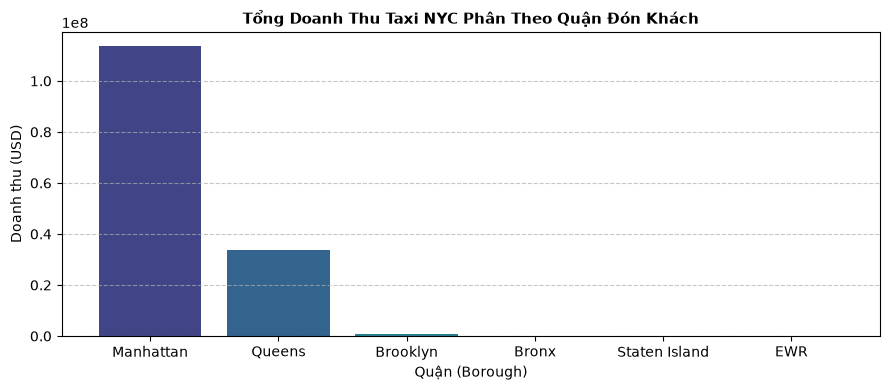

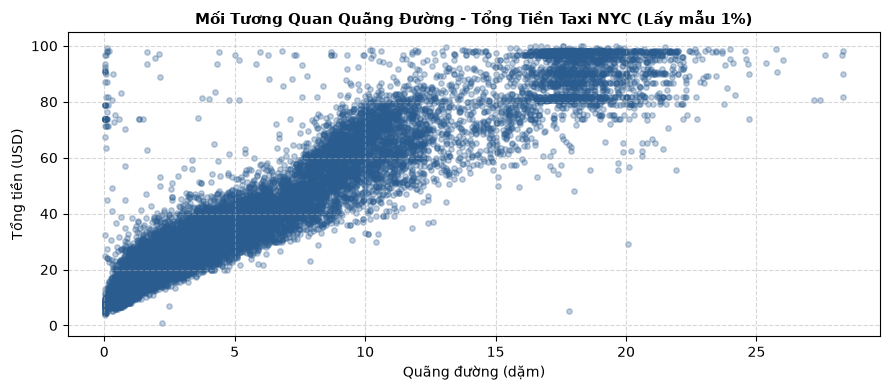

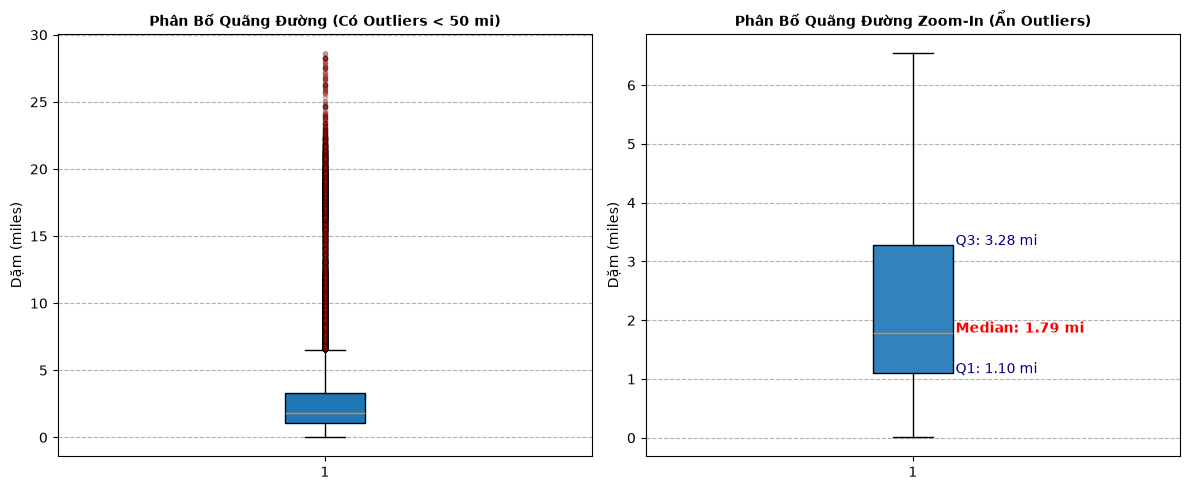

In [15]:
# Lấy mẫu 1% dữ liệu phục vụ trực quan hóa
pdf_sample = df_joined \
    .filter(F.col("pickup_borough").isNotNull() & (~F.col("pickup_borough").isin("Unknown", "N/A"))) \
    .sample(fraction=0.01, seed=42) \
    .toPandas()

# ------------------------------------------------------------------------------
# 7.1 Biểu đồ Cột: Doanh thu theo Quận
# ------------------------------------------------------------------------------
pdf_borough = df_borough_summary.toPandas()
plt.figure(figsize=(9, 4))
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(pdf_borough)))
plt.bar(pdf_borough["pickup_borough"], pdf_borough["total_revenue"], color=colors)
plt.title("Tổng Doanh Thu Taxi NYC Phân Theo Quận Đón Khách", fontsize=11, fontweight="bold")
plt.xlabel("Quận (Borough)"); plt.ylabel("Doanh thu (USD)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------------------------
# 7.2 Biểu đồ Scatter: Quãng đường vs Tổng tiền (Tương quan)
# ------------------------------------------------------------------------------
pdf_scatter = pdf_sample[pdf_sample['total_amount'] < 100]
plt.figure(figsize=(9, 4))
plt.scatter(pdf_scatter["trip_distance"], pdf_scatter["total_amount"], alpha=0.3, color="#2b5c8f", s=15)
plt.title("Mối Tương Quan Quãng Đường - Tổng Tiền Taxi NYC (Lấy mẫu 1%)", fontsize=11, fontweight="bold")
plt.xlabel("Quãng đường (dặm)"); plt.ylabel("Tổng tiền (USD)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------------------------
# 7.3 Biểu đồ Boxplot Subplots: Phân bố Quãng đường (Toàn cảnh vs Zoom-in)
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Có Outliers (< 50 miles)
ax1.boxplot(pdf_sample[pdf_sample["trip_distance"] < 50]["trip_distance"], patch_artist=True, showfliers=True,
            flierprops=dict(marker='o', markerfacecolor='red', alpha=0.2, markersize=3))
ax1.set_title("Phân Bố Quãng Đường (Có Outliers < 50 mi)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Dặm (miles)"); ax1.grid(axis='y', linestyle='--')

# Subplot 2: Zoom-in (Ẩn Outliers & Đánh dấu chỉ số)
bp2 = ax2.boxplot(pdf_sample["trip_distance"], patch_artist=True, showfliers=False)
bp2['boxes'][0].set_facecolor('#3182bd')

q1 = np.percentile(pdf_sample["trip_distance"], 25)
med = np.median(pdf_sample["trip_distance"])
q3 = np.percentile(pdf_sample["trip_distance"], 75)

ax2.text(1.08, q1, f"Q1: {q1:.2f} mi", color='darkblue')
ax2.text(1.08, med, f"Median: {med:.2f} mi", color='red', fontweight='bold')
ax2.text(1.08, q3, f"Q3: {q3:.2f} mi", color='darkblue')
ax2.set_title("Phân Bố Quãng Đường Zoom-In (Ẩn Outliers)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Dặm (miles)"); ax2.grid(axis='y', linestyle='--')

plt.tight_layout(); plt.show()

BƯỚC 8: PHÂN TÍCH NÂNG CAO VỚI WINDOW FUNCTIONS & CẤU TRÚC PHỨC TẠP
8.1 Hàm Cửa sổ (Window Functions)
Tính doanh thu tích lũy cộng dồn (Running Total) và so sánh chênh lệch doanh thu với ngày liền trước (Lag) theo từng Quận.

In [16]:
from pyspark.sql.window import Window

# Gom nhóm doanh thu theo Quận và Ngày
df_daily_borough = df_joined \
    .filter(F.col("pickup_borough").isNotNull() & (~F.col("pickup_borough").isin("Unknown", "N/A"))) \
    .groupBy("pickup_borough", "pickup_date") \
    .agg(F.round(F.sum("total_amount"), 2).alias("daily_revenue"))

# Định nghĩa cửa sổ phân vùng theo Quận và sắp xếp theo Ngày
window_spec = Window.partitionBy("pickup_borough").orderBy("pickup_date")

df_windowed = df_daily_borough \
    .withColumn("running_total_revenue", F.round(F.sum("daily_revenue").over(window_spec), 2)) \
    .withColumn("prev_day_revenue", F.lag("daily_revenue", 1).over(window_spec)) \
    .withColumn("revenue_diff", F.round(F.col("daily_revenue") - F.col("prev_day_revenue"), 2))

print("=== PHÂN TÍCH DOANH THU CỘNG DỒN VÀ CHÊNH LỆCH NGÀY (WINDOWING) ===")
df_windowed.filter(F.col("pickup_borough") == "Manhattan").orderBy("pickup_date").show(10)

=== PHÂN TÍCH DOANH THU CỘNG DỒN VÀ CHÊNH LỆCH NGÀY (WINDOWING) ===


+--------------+-----------+-------------+---------------------+----------------+------------+
|pickup_borough|pickup_date|daily_revenue|running_total_revenue|prev_day_revenue|revenue_diff|
+--------------+-----------+-------------+---------------------+----------------+------------+
|     Manhattan| 2008-12-31|         45.0|                 45.0|            NULL|        NULL|
|     Manhattan| 2009-01-01|         16.4|                 61.4|            45.0|       -28.6|
|     Manhattan| 2022-12-31|       473.03|               534.43|            16.4|      456.63|
|     Manhattan| 2023-01-01|   1444940.06|           1445474.49|          473.03|  1444467.03|
|     Manhattan| 2023-01-02|   1138503.31|            2583977.8|      1444940.06|  -306436.75|
|     Manhattan| 2023-01-03|   1503786.03|           4087763.83|      1138503.31|   365282.72|
|     Manhattan| 2023-01-04|   1758112.72|           5845876.55|      1503786.03|   254326.69|
|     Manhattan| 2023-01-05|   1884046.79|        

8.2 Gom nhóm nâng cao với Struct & Array (Entity Profiling)

In [17]:
# Đếm toàn bộ nhóm trước, chỉ đưa 10 hàng mẫu mỗi quận vào collect_list.
high_value_rows = df_joined.filter(F.col('total_amount')>50)
profile_count_window = Window.partitionBy('pickup_borough')
profile_sample_window = Window.partitionBy('pickup_borough').orderBy(
    'tpep_pickup_datetime','trip_distance','total_amount','PULocationID','DOLocationID')
profile_ranked = (high_value_rows
    .withColumn('total_high_value_count',F.count('*').over(profile_count_window))
    .withColumn('sample_rank',F.row_number().over(profile_sample_window)))
df_profile = (profile_ranked.filter(F.col('sample_rank')<=10).groupBy('pickup_borough').agg(
    F.sort_array(F.collect_list(F.struct('tpep_pickup_datetime','trip_distance','total_amount'))).alias('high_value_trips'),
    F.max('total_high_value_count').alias('total_high_value_count')))
assert df_profile.filter(F.size('high_value_trips')>10).count()==0
df_profile.select('pickup_borough','total_high_value_count').show()


+--------------+----------------------+
|pickup_borough|total_high_value_count|
+--------------+----------------------+
|         Bronx|                  1033|
|      Brooklyn|                  3640|
|           EWR|                    64|
|     Manhattan|                184123|
| Staten Island|                   306|
|        Queens|                382316|
+--------------+----------------------+



Bài tập 4 (Window Functions):
Sử dụng Window.partitionBy("pickup_borough").orderBy(F.desc("daily_revenue")) và hàm F.row_number(), hãy tìm Top 3 ngày có doanh thu cao nhất của từng Quận.

In [18]:
rank_window = Window.partitionBy('pickup_borough').orderBy(F.desc('daily_revenue'), F.asc('pickup_date'))
top3_days = (df_daily_borough.withColumn('rank', F.row_number().over(rank_window))
             .filter(F.col('rank') <= 3).orderBy('pickup_borough', 'rank'))
top3_days.show(30, truncate=False)

+--------------+-----------+-------------+----+
|pickup_borough|pickup_date|daily_revenue|rank|
+--------------+-----------+-------------+----+
|Bronx         |2023-02-24 |5310.68      |1   |
|Bronx         |2023-02-23 |5169.06      |2   |
|Bronx         |2023-02-27 |4698.95      |3   |
|Brooklyn      |2023-01-01 |21104.32     |1   |
|Brooklyn      |2023-01-21 |19506.36     |2   |
|Brooklyn      |2023-02-25 |17884.99     |3   |
|EWR           |2023-01-01 |989.29       |1   |
|EWR           |2023-02-17 |650.77       |2   |
|EWR           |2023-01-03 |455.0        |3   |
|Manhattan     |2023-02-09 |2329848.63   |1   |
|Manhattan     |2023-02-15 |2321026.63   |2   |
|Manhattan     |2023-02-23 |2298151.23   |3   |
|Queens        |2023-01-03 |749347.13    |1   |
|Queens        |2023-02-20 |743303.84    |2   |
|Queens        |2023-01-13 |736081.4     |3   |
|Staten Island |2023-01-10 |903.21       |1   |
|Staten Island |2023-01-09 |816.56       |2   |
|Staten Island |2023-01-15 |716.65      

Dùng ngày tăng dần để phá hòa doanh thu: mỗi quận tối đa đúng 3 ngày, thứ tự tái lập được.

BƯỚC 9: TRUY VẤN SPARKSQL & XUẤT DỮ LIỆU TỐI ƯU (PARTITIONING)

9.1 Đăng ký Temporary View và Thực thi SparkSQL

In [19]:
# Đăng ký DataFrame thành bảng tạm trong Spark catalog
df_joined.createOrReplaceTempView("vw_nyc_taxi")

# Thực hiện truy vấn SparkSQL phức tạp
spark_sql_query = """
    SELECT 
        pickup_borough,
        COUNT(*) AS total_trips,
        ROUND(AVG(trip_distance), 2) AS avg_distance,
        ROUND(AVG(total_amount), 2) AS avg_fare,
        ROUND(SUM(tip_amount) / SUM(total_amount) * 100, 2) AS tip_percentage
    FROM vw_nyc_taxi
    WHERE pickup_borough NOT IN ('Unknown', 'N/A') AND pickup_borough IS NOT NULL
    GROUP BY pickup_borough
    HAVING total_trips > 1000
    ORDER BY tip_percentage DESC
"""

print("=== KẾT QUẢ TRUY VẤN SPARKSQL ===")
spark.sql(spark_sql_query).show()

=== KẾT QUẢ TRUY VẤN SPARKSQL ===


+--------------+-----------+------------+--------+--------------+
|pickup_borough|total_trips|avg_distance|avg_fare|tip_percentage|
+--------------+-----------+------------+--------+--------------+
|     Manhattan|    4999130|        2.38|    22.7|          12.8|
|        Queens|     485168|       12.57|   69.23|         11.84|
|      Brooklyn|      25061|        5.06|    31.2|           8.4|
|         Bronx|       5578|        6.73|   33.57|          1.61|
+--------------+-----------+------------+--------+--------------+



9.2 Xuất dữ liệu sạch ra định dạng Parquet theo Phân vùng (Partitioning)

In [20]:
# Ghi dữ liệu sạch ra đĩa dưới dạng Parquet được phân vùng theo Ngày đón khách
output_path = "./nyc_data/output_clean_taxi_parquet"

df_joined.write \
    .mode("overwrite") \
    .partitionBy("pickup_date") \
    .parquet(output_path)

print(f"Đã ghi tập dữ liệu sạch thành công vào: {output_path}")

Đã ghi tập dữ liệu sạch thành công vào: ./nyc_data/output_clean_taxi_parquet


Bài tập 5: 

1: Phân tích Tuyến đường Huyết mạch theo Khung giờ
Tìm Top 5 cặp tuyến đường phổ biến nhất (`PULocationID` -> `DOLocationID` >= 5,000 chuyến). Tính thời gian di chuyển trung bình trong Giờ Cao Điểm (7h-9h & 17h-19h) so với Giờ Thấp Điểm (22h-4h).

2: Tối ưu hóa hiệu năng Partition Pruning
- Ghi `df_clean` ra đĩa dạng Parquet phân vùng theo ngày: `df_clean.write.partitionBy('pickup_date').mode('overwrite').parquet('./nyc_data_partitioned')`
- Nạp lại dữ liệu phân vùng và so sánh thời gian truy vấn ngày `'2023-01-15'` giữa `df_clean` và `df_partitioned`.

### Lời giải bài 5.1 — Tuyến đường theo khung giờ
Tuyến là cặp **có hướng** đón → trả; chọn tuyến có ít nhất 5.000 chuyến trên toàn bộ dữ liệu sạch, rồi lấy 5 tuyến nhiều chuyến nhất.
Quy ước giờ theo `hour`: cao điểm gồm 7, 8, 9, 17, 18, 19; thấp điểm gồm 22, 23, 0, 1, 2, 3, 4.
Không gộp các giờ còn lại vào thấp điểm. Tuyến thiếu quan sát ở một khung giờ giữ `NULL` thay vì gán trung bình bằng 0.

In [21]:
route_counts = df_clean.groupBy('PULocationID', 'DOLocationID').count()
top5_routes = (route_counts.filter(F.col('count') >= 5000)
    .orderBy(F.desc('count'), 'PULocationID', 'DOLocationID').limit(5)
    .withColumnRenamed('count', 'total_trips'))
routes = (df_clean.join(F.broadcast(top5_routes), ['PULocationID', 'DOLocationID'])
    .withColumn('pickup_hour', F.hour('tpep_pickup_datetime')))
peak = F.col('pickup_hour').isin(7, 8, 9, 17, 18, 19)
off_peak = F.col('pickup_hour').isin(22, 23, 0, 1, 2, 3, 4)
route_comparison = (routes.groupBy('PULocationID','DOLocationID','total_trips').agg(
    F.sum(F.when(peak,1).otherwise(0)).alias('peak_count'),
    F.round(F.avg(F.when(peak,F.col('trip_duration_min'))),2).alias('peak_mean_minutes'),
    F.sum(F.when(off_peak,1).otherwise(0)).alias('off_peak_count'),
    F.round(F.avg(F.when(off_peak,F.col('trip_duration_min'))),2).alias('off_peak_mean_minutes'))
    .withColumn('difference_minutes', F.round(F.col('peak_mean_minutes')-F.col('off_peak_mean_minutes'),2)))
route_comparison.orderBy(F.desc('total_trips')).show(truncate=False)

+------------+------------+-----------+----------+-----------------+--------------+---------------------+------------------+
|PULocationID|DOLocationID|total_trips|peak_count|peak_mean_minutes|off_peak_count|off_peak_mean_minutes|difference_minutes|
+------------+------------+-----------+----------+-----------------+--------------+---------------------+------------------+
|237         |236         |40402      |12970     |7.69             |2088          |7.88                 |-0.19             |
|236         |237         |34416      |11915     |8.44             |676           |5.2                  |3.24              |
|236         |236         |26334      |8947      |7.04             |811           |3.92                 |3.12              |
|237         |237         |25469      |8086      |6.32             |1375          |8.39                 |-2.07             |
|161         |237         |17428      |5437      |8.57             |1045          |9.2                  |-0.63             |


### Đọc kết quả tuyến đường: trung bình có bị kéo lên không?
Bảng trên trả lời đúng yêu cầu so sánh trung bình. Tuy nhiên, trung bình thấp điểm
cao hơn cao điểm trên một số tuyến cần được kiểm tra trước khi giải thích bằng ùn tắc.
Tính thêm median, P90 và số chuyến trên 60 phút; đây là kiểm tra độ nhạy, không thay
định nghĩa dữ liệu sạch. Mỗi cặp ID là một vùng đón/trả, chưa phải lộ trình đường phố
cố định. Tách ngày thường/cuối tuần để quan sát thêm khác biệt thành phần chuyến đi.

In [22]:
route_detail = (routes.withColumn('period', F.when(peak,'Cao điểm').when(off_peak,'Thấp điểm'))
    .filter(F.col('period').isNotNull())
    .withColumn('day_type', F.when(F.dayofweek('pickup_date').isin(1,7),'Cuối tuần').otherwise('Ngày thường')))
route_summary = (route_detail.groupBy('PULocationID','DOLocationID','period').agg(
    F.count('*').alias('n'), F.avg('trip_duration_min').alias('mean_minutes'),
    F.percentile_approx('trip_duration_min',0.5,10000).alias('median_minutes'),
    F.percentile_approx('trip_duration_min',0.9,10000).alias('p90_minutes'),
    F.sum(F.when(F.col('trip_duration_min')>60,1).otherwise(0)).alias('over_60_minutes'),
    F.avg(F.when(F.col('trip_duration_min')<=60,F.col('trip_duration_min'))).alias('mean_if_at_most_60')))
(route_summary.orderBy('PULocationID','DOLocationID','period').select(*[
    F.round(k,2).alias(k) if k in ['mean_minutes','median_minutes','p90_minutes','mean_if_at_most_60']
    else F.col(k) for k in route_summary.columns]).show(10,truncate=False))
day_comparison = (route_detail.groupBy('PULocationID','DOLocationID','day_type').agg(
    F.sum(F.when(F.col('period')=='Cao điểm',1).otherwise(0)).alias('peak_n'),
    F.sum(F.when(F.col('period')=='Thấp điểm',1).otherwise(0)).alias('off_peak_n'),
    F.round(F.avg(F.when(F.col('period')=='Cao điểm',F.col('trip_duration_min'))),2).alias('peak_mean'),
    F.round(F.avg(F.when(F.col('period')=='Thấp điểm',F.col('trip_duration_min'))),2).alias('off_peak_mean')))
day_comparison.orderBy('PULocationID','DOLocationID','day_type').show(10,truncate=False)
details = {(r.PULocationID,r.DOLocationID,r.period):r for r in route_summary.collect()}
for r in route_comparison.orderBy(F.desc('total_trips')).collect():
    high = details.get((r.PULocationID,r.DOLocationID,'Cao điểm'))
    low = details.get((r.PULocationID,r.DOLocationID,'Thấp điểm'))
    if high is None or low is None:
        print(f'{r.PULocationID}→{r.DOLocationID}: thiếu một khung giờ để so sánh.')
        continue
    gap = high.mean_minutes-low.mean_minutes
    median_gap = high.median_minutes-low.median_minutes
    print(f'{r.PULocationID}→{r.DOLocationID}: cao điểm trừ thấp điểm '
          f'mean={gap:+.2f} phút; median={median_gap:+.2f} phút; '
          f'chuyến >60 phút: cao điểm {high.over_60_minutes}/{high.n}, '
          f'thấp điểm {low.over_60_minutes}/{low.n}.')
    if gap*median_gap < 0:
        print('  Mean và median cho hai chiều khác nhau: kết luận phụ thuộc thước đo, cần xem phần đuôi.')
print('Không suy ra tác động nhân quả của giờ cao điểm từ so sánh quan sát này.')

+------------+------------+---------+-----+------------+--------------+-----------+---------------+------------------+
|PULocationID|DOLocationID|period   |n    |mean_minutes|median_minutes|p90_minutes|over_60_minutes|mean_if_at_most_60|
+------------+------------+---------+-----+------------+--------------+-----------+---------------+------------------+
|161         |237         |Cao điểm |5437 |8.57        |8.08          |13.1       |1              |8.56              |
|161         |237         |Thấp điểm|1045 |9.2         |6.12          |9.83       |2              |6.48              |
|236         |236         |Cao điểm |8947 |7.04        |3.98          |7.52       |18             |4.83              |
|236         |236         |Thấp điểm|811  |3.92        |3.27          |6.2        |1              |3.84              |
|236         |237         |Cao điểm |11915|8.44        |6.98          |11.23      |10             |7.37              |
|236         |237         |Thấp điểm|676  |5.2  

+------------+------------+-----------+------+----------+---------+-------------+
|PULocationID|DOLocationID|day_type   |peak_n|off_peak_n|peak_mean|off_peak_mean|
+------------+------------+-----------+------+----------+---------+-------------+
|161         |237         |Cuối tuần  |762   |257       |6.88     |12.06        |
|161         |237         |Ngày thường|4675  |788       |8.84     |8.26         |
|236         |236         |Cuối tuần  |1458  |295       |6.4      |4.06         |
|236         |236         |Ngày thường|7489  |516       |7.16     |3.84         |
|236         |237         |Cuối tuần  |1888  |240       |6.06     |4.99         |
|236         |237         |Ngày thường|10027 |436       |8.89     |5.31         |
|237         |236         |Cuối tuần  |1866  |599       |6.02     |12.11        |
|237         |236         |Ngày thường|11104 |1489      |7.98     |6.17         |
|237         |237         |Cuối tuần  |1260  |431       |5.95     |10.68        |
|237         |23

237→236: cao điểm trừ thấp điểm mean=-0.18 phút; median=+1.36 phút; chuyến >60 phút: cao điểm 11/12970, thấp điểm 4/2088.
  Mean và median cho hai chiều khác nhau: kết luận phụ thuộc thước đo, cần xem phần đuôi.
236→237: cao điểm trừ thấp điểm mean=+3.24 phút; median=+2.20 phút; chuyến >60 phút: cao điểm 10/11915, thấp điểm 0/676.
236→236: cao điểm trừ thấp điểm mean=+3.12 phút; median=+0.71 phút; chuyến >60 phút: cao điểm 18/8947, thấp điểm 1/811.
237→237: cao điểm trừ thấp điểm mean=-2.07 phút; median=+0.87 phút; chuyến >60 phút: cao điểm 9/8086, thấp điểm 4/1375.
  Mean và median cho hai chiều khác nhau: kết luận phụ thuộc thước đo, cần xem phần đuôi.
161→237: cao điểm trừ thấp điểm mean=-0.63 phút; median=+1.96 phút; chuyến >60 phút: cao điểm 1/5437, thấp điểm 2/1045.
  Mean và median cho hai chiều khác nhau: kết luận phụ thuộc thước đo, cần xem phần đuôi.
Không suy ra tác động nhân quả của giờ cao điểm từ so sánh quan sát này.


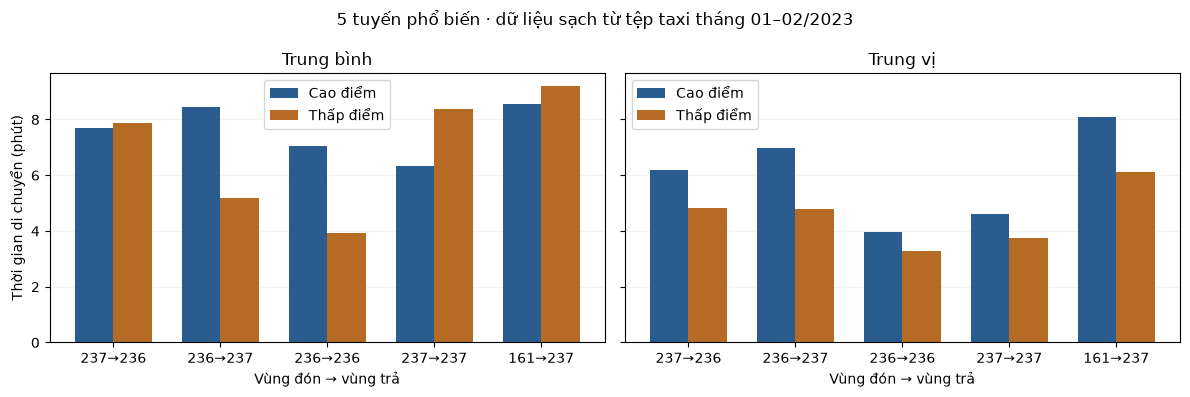

In [23]:
# Cùng thứ tự tuyến, cùng đơn vị; giữ cả mean và median để thấy ảnh hưởng phần đuôi.
route_plot = route_comparison.orderBy(F.desc('total_trips')).collect()
route_labels = [f'{r.PULocationID}→{r.DOLocationID}' for r in route_plot]
fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
positions = np.arange(len(route_plot))
for ax,field,title in [(axes[0],'mean_minutes','Trung bình'),(axes[1],'median_minutes','Trung vị')]:
    for offset,period,color in [(-0.18,'Cao điểm','#2b5c8f'),(0.18,'Thấp điểm','#b56b24')]:
        values = [details[(r.PULocationID,r.DOLocationID,period)][field] for r in route_plot]
        ax.bar(positions+offset,values,width=0.36,label=period,color=color)
    ax.set(xticks=positions,xticklabels=route_labels,xlabel='Vùng đón → vùng trả',title=title,ylim=(0,None))
    ax.grid(axis='y',alpha=0.15); ax.set_axisbelow(True); ax.legend()
axes[0].set_ylabel('Thời gian di chuyển (phút)')
fig.suptitle('5 tuyến phổ biến · dữ liệu sạch từ tệp taxi tháng 01–02/2023')
plt.tight_layout(); plt.show()

**Nhận xét từ bảng:** cả ba tuyến 237→236, 237→237 và 161→237 có mean cao điểm thấp hơn thấp điểm, nhưng median cao điểm đều cao hơn. Ví dụ 237→236 có mean 7,69 so với 7,88 phút, trong khi median là 6,18 so với 4,82 phút. Khi chỉ xét chuyến không quá 60 phút để kiểm tra độ nhạy, mean của tuyến này là 6,65 so với 5,16 phút. Vì vậy chiều chênh lệch ban đầu không bền với thước đo và phần đuôi; chưa thể giải thích là xe chạy nhanh hơn trong giờ cao điểm. Bảng ngày thường/cuối tuần cho thấy thành phần ngày cũng thay đổi kết quả. Vẫn giữ toàn bộ chuyến hợp lệ trong đáp án chính, không loại chuyến dài chỉ để đổi chiều kết luận.

### Lời giải bài 5.2 — Partition pruning
Đo bằng `perf_counter`, có action `collect()` trên phép đếm để Spark thực thi thật. Dùng cùng số bản ghi và cùng điều kiện lọc, không cache hai nguồn.
Đo luân phiên 3 lượt và lấy median; ghi dữ liệu không tính vào thời gian truy vấn.
Đây là phép đo trong một máy, bộ đệm hệ điều hành/JVM vẫn ảnh hưởng; cần đọc `PartitionFilters` trong kế hoạch để kiểm chứng pruning, không suy từ tốc độ đơn thuần.

Trong đề, `df_clean` còn chứa kế hoạch làm sạch, còn Parquet đã được ghi sẵn. Tỷ số thời gian vì thế còn bao gồm chi phí tính lại pipeline và cách lưu trữ; không thể quy toàn bộ chênh lệch cho riêng pruning.

In [24]:
from time import perf_counter
from statistics import median
partition_path = './nyc_data_partitioned'
df_clean.write.partitionBy('pickup_date').mode('overwrite').parquet(partition_path)
df_partitioned = spark.read.parquet(partition_path)
target_date = F.lit('2023-01-15').cast('date')
print('Kế hoạch đọc phân vùng:')
df_partitioned.filter(F.col('pickup_date') == target_date).explain('formatted')

def timed_count(frame):
    start = perf_counter()
    value = frame.filter(F.col('pickup_date') == target_date).agg(F.count('*').alias('n')).collect()[0]['n']
    return value, perf_counter() - start

measurements = {'df_clean': [], 'df_partitioned': []}
counts = {}
for repeat in range(3):
    sources = [('df_clean', df_clean), ('df_partitioned', df_partitioned)]
    if repeat % 2:
        sources.reverse()
    for name, frame in sources:
        spark.catalog.clearCache()
        counts[name], elapsed = timed_count(frame)
        measurements[name].append(elapsed)
assert counts['df_clean'] == counts['df_partitioned'], counts
for name, times in measurements.items():
    print(f'{name}: n={counts[name]:,}; các lần={times}; median={median(times):.3f}s')
ratio = median(measurements['df_clean']) / median(measurements['df_partitioned'])
print(f'Tỷ số thời gian df_clean / df_partitioned = {ratio:.2f}')

Kế hoạch đọc phân vùng:
== Physical Plan ==
* ColumnarToRow (2)
+- Scan parquet  (1)


(1) Scan parquet 
Output [22]: [VendorID#4633L, tpep_pickup_datetime#4634, tpep_dropoff_datetime#4635, passenger_count#4636, trip_distance#4637, RatecodeID#4638, store_and_fwd_flag#4639, PULocationID#4640L, DOLocationID#4641L, payment_type#4642L, fare_amount#4643, extra#4644, mta_tax#4645, tip_amount#4646, tolls_amount#4647, improvement_surcharge#4648, total_amount#4649, congestion_surcharge#4650, airport_fee#4651, trip_duration_min#4652, speed_mph#4653, pickup_date#4654]
Batched: true
Location: InMemoryFileIndex [file:/home/kent/KentProject/BaiTapPhanTichDuLieuLon/BaiTapMonPhanTichKhaiPhaDuLieuLon/nyc_data_partitioned]
PartitionFilters: [isnotnull(pickup_date#4654), (pickup_date#4654 = 2023-01-15)]
ReadSchema: struct<VendorID:bigint,tpep_pickup_datetime:timestamp_ntz,tpep_dropoff_datetime:timestamp_ntz,passenger_count:double,trip_distance:double,RatecodeID:double,store_and_fwd_flag:string,PULocation

df_clean: n=89,240; các lần=[4.483785710999655, 4.667901738001092, 4.575376786000561]; median=4.575s
df_partitioned: n=89,240; các lần=[0.08403155300038634, 0.053455620000022464, 0.07724842400057241]; median=0.077s
Tỷ số thời gian df_clean / df_partitioned = 59.23


### Benchmark bổ sung: hai nguồn Parquet đã vật chất hóa
Phép đo theo đề ở trên so sánh pipeline với dữ liệu đã ghi nên có nhiều yếu tố cùng thay đổi.
Đối chứng dưới đây ghi cùng `df_clean` thành Parquet không phân vùng, rồi so với Parquet
phân vùng đã có. Hai bên cùng đếm chuyến và cộng `total_amount`, có đọc làm nóng trước khi đo luân phiên.
Phép cộng buộc truy vấn đọc giá trị cột tiền; chỉ `COUNT(*)` có thể tận dụng thống kê
footer Parquet mà không đọc các giá trị dữ liệu, nên không đại diện cho truy vấn doanh thu.
Chênh lệch vẫn gồm bố trí/số lượng tệp và metadata; `PartitionFilters` ở trên mới là bằng
chứng Spark đã áp dụng pruning. Không coi tỷ số thời gian là hằng số của thuật toán.

In [25]:
unpartitioned_path = './nyc_data/output_clean_unpartitioned_control'
df_clean.write.mode('overwrite').parquet(unpartitioned_path)
df_unpartitioned = spark.read.parquet(unpartitioned_path)
controls = [('Parquet không phân vùng',df_unpartitioned),('Parquet phân vùng',df_partitioned)]
def timed_control(frame):
    start = perf_counter()
    result = (frame.filter(F.col('pickup_date')==target_date)
        .agg(F.count('*').alias('n'),F.round(F.sum('total_amount'),2).alias('total_USD')).first())
    return result,perf_counter()-start

for _,frame in controls:
    timed_control(frame)  # Làm nóng cả hai nguồn; không đưa vào số đo.
control_times = {name:[] for name,_ in controls}
control_counts = {}
control_totals = {}
for repeat in range(5):
    for name,frame in (controls if repeat%2==0 else list(reversed(controls))):
        spark.catalog.clearCache()
        result,elapsed = timed_control(frame)
        control_counts[name] = result.n
        control_totals[name] = result.total_USD
        control_times[name].append(elapsed)
assert len(set(control_counts.values())) == 1
assert len(set(control_totals.values())) == 1
assert next(iter(control_counts.values())) == counts['df_clean']
for name,times in control_times.items():
    print(f'{name}: n={control_counts[name]:,}; tổng={control_totals[name]:,.2f} USD; median={median(times):.3f}s; các lượt={times}')
print('Tỷ số median không phân vùng / phân vùng:',
      median(control_times[controls[0][0]])/median(control_times[controls[1][0]]))

Parquet không phân vùng: n=89,240; tổng=2,384,969.40 USD; median=0.059s; các lượt=[0.08270205500048178, 0.06856418200004555, 0.05929543099955481, 0.05329910500040569, 0.05834566100020311]
Parquet phân vùng: n=89,240; tổng=2,384,969.40 USD; median=0.054s; các lượt=[0.07082930199976545, 0.08541951699953643, 0.04844287000014447, 0.04510787899926072, 0.0536542459994962]
Tỷ số median không phân vùng / phân vùng: 1.1051395820586423


**Kết quả đối chứng:** hai nguồn cùng trả 89.240 chuyến, tổng 2.384.969,40 USD. Median lần chạy này khoảng 0,059 giây khi không phân vùng và 0,054 giây khi phân vùng, tỷ số khoảng 1,11. Các lượt đo có thời gian chồng lấn; chênh lệch nhỏ chưa chứng minh mức tăng tốc ổn định. Pruning có xuất hiện trong kế hoạch, nhưng hiệu quả phụ thuộc truy vấn, số tệp và bộ đệm. Vì vậy không dùng mức tăng tốc của phép đo pipeline ban đầu để đại diện riêng cho pruning.

### Đối chiếu tổng số dòng và khóa nối
Bảng vùng phải có duy nhất một hàng cho mỗi `LocationID`. Nối trái không được làm
tăng số chuyến. Tổng pivot thẻ/tiền mặt phải bằng số chuyến đủ điều kiện trước pivot.

In [26]:
assert df_zones.filter(F.col('LocationID').isNull()).count() == 0
assert df_zones.groupBy('LocationID').count().filter(F.col('count')>1).count() == 0
joined_count = df_joined.count()
assert joined_count == clean_records, (joined_count,clean_records)
eligible_payment = df_joined.filter(F.col('pickup_borough').isNotNull()
    & ~F.col('pickup_borough').isin('Unknown','N/A') & F.col('payment_type').isin(1,2)).count()
pivot_count = pivot_payment.agg(F.sum(F.col('so_chuyen_the')+F.col('so_chuyen_tien_mat'))).first()[0]
assert pivot_count == eligible_payment, (pivot_count,eligible_payment)
print(f'Đối chiếu đạt: {joined_count:,} chuyến sau join; {pivot_count:,} chuyến trong pivot thanh toán.')

Đối chiếu đạt: 5,515,455 chuyến sau join; 5,466,749 chuyến trong pivot thanh toán.


## Kiểm tra và kết luận
P99.9 dùng sai số hạng `0.0001`, nhỏ hơn xác suất phần đuôi `0.001`; sai số `0.01` của đề gốc quá lớn để phân biệt đúng đuôi này.
Hồ sơ cước cao đếm đầy đủ chuyến từng quận bằng window, nhưng lọc còn tối đa 10 hàng mỗi quận trước `collect_list`, tránh gom toàn bộ nhóm vào một mảng rồi mới cắt.
Các kiểm tra đối chiếu xác nhận join không nhân số chuyến và pivot không làm mất số chuyến đủ điều kiện. Bộ lọc chỉ định nghĩa tập phân tích theo các quy tắc đã chọn, không chứng minh mọi bản ghi còn lại đều hoàn toàn chính xác.


In [27]:
spark.stop()